# Тюнинг линейной регрессии и ошибки

### О задании

В этом задании вы:
- обучите линейную регрессию, познакомитесь с метриками качества в задачах регресии

In [2]:
%pylab inline
import pandas as pd

from sklearn.base import BaseEstimator
from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split

%pylab is deprecated, use %matplotlib inline and import the required libraries.
Populating the interactive namespace from numpy and matplotlib


## Часть 1. Линейная регрессия

Для начала загрузим данные и разделим их на обучающую и тестовую выборки в соотношении 7 к 3. Зачем так делать? Когда вы проверяете себя на данных на которых не обучались, вы можете быть уверены что не переобучились. Таким образом если качество на 70% датасета (оубчающей выборке) растёт, а на тестовой выборке падает, то модель начала запоминать датасет (переобучилась), вы что-то делаете не так.


In [3]:
data = load_diabetes()
X_train, X_test, y_train, y_test = train_test_split(data.data, data.target, train_size=0.7, random_state=241)

__Задание 1.__ Обучение линейной регрессии.

**(4 балла)**

Обучите линейную регрессию с $L_1$ (Lasso) и $L_2$ (Ridge) регуляризаторами (используйте параметры по умолчанию). Посмотрите, какое количество коэффициентов близко к 0 (степень близости к 0 определите сами из разумных пределов). Постройте график зависимости числа ненулевых коэффициентов от коэффицента регуляризации (перебирайте значения по логарифмической сетке от $10^{-3}$ до $10^3$).

Спойлер - при большом гиперпараметре регуляризации все параметры стремятся к нулю. На графике это должно быть видно.

Постройте графики коэффициентов регрессии от итерации обучения

In [4]:
from sklearn import datasets, linear_model
from sklearn.linear_model import Ridge, Lasso
import numpy as np

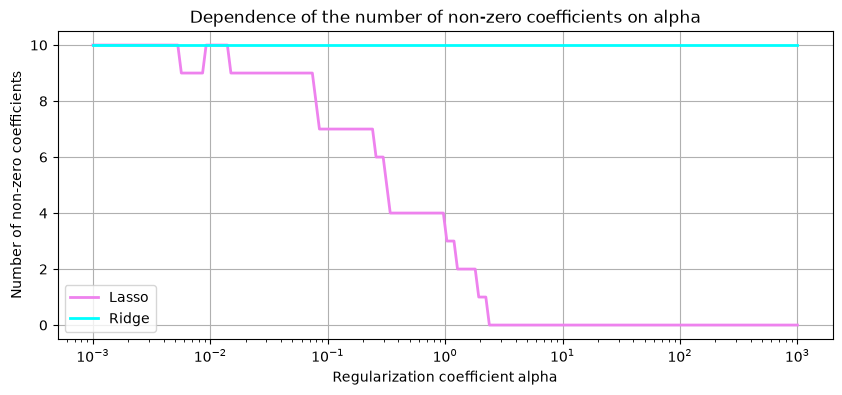

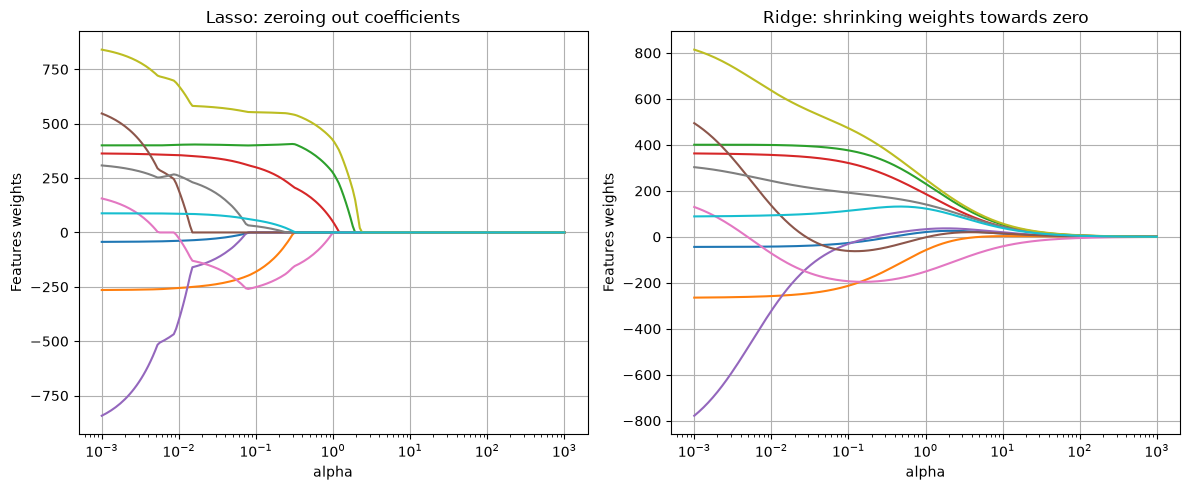

In [5]:
alphas = np.logspace(-3, 3, 200) #create a logarithmic grid

lasso_coefs = []
ridge_coefs = []

for a in alphas:
    #Lasso
    lasso = Lasso(alpha = a, random_state=247, max_iter=10000)
    lasso.fit(X_train, y_train)
    lasso_coefs.append(lasso.coef_)


    #Ridge
    ridge = Ridge(alpha=a, random_state=247)
    ridge.fit(X_train, y_train)
    ridge_coefs.append(ridge.coef_)


lasso_coefs = np.array(lasso_coefs)
ridge_coefs = np.array(ridge_coefs)

non_zero_lasso = [np.sum(np.abs(coef) > 1e-5) for coef in lasso_coefs]
non_zero_ridge = [np.sum(np.abs(coef) > 1e-5) for coef in ridge_coefs]


#Graph of the number of non-zero coefficients as a function of alpha
plt.figure(figsize=(10, 4))
plt.plot(alphas, non_zero_lasso, label='Lasso', color='violet', linewidth=2)
plt.plot(alphas, non_zero_ridge, label='Ridge', color='cyan', linewidth=2)
plt.xscale('log')
plt.xlabel('Regularization coefficient alpha')
plt.ylabel('Number of non-zero coefficients')
plt.title('Dependence of the number of non-zero coefficients on alpha')
plt.legend()
plt.grid(True)
plt.show()


#Plotting  the changes in the regression coefficients themselves
plt.figure(figsize=(12,5))
plt.subplot(1, 2, 1)
plt.plot(alphas, lasso_coefs)
plt.xscale('log')
plt.xlabel('alpha')
plt.ylabel('Features weights')
plt.title('Lasso: zeroing out coefficients')
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(alphas, ridge_coefs)
plt.xscale('log')
plt.xlabel('alpha')
plt.ylabel('Features weights')
plt.title('Ridge: shrinking weights towards zero')
plt.grid(True)

plt.tight_layout()
plt.show()



Посчитайте для Ridge-регрессии следующие метрики: $RMSE$, $MAE$, $R^2$.

In [6]:
from sklearn.model_selection import cross_val_score
from sklearn.model_selection import cross_val_predict

In [7]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


# Train a standart ridge regression model
ridge_model = Ridge(alpha=1.0, random_state=241)
ridge_model.fit(X_train, y_train)

# Make predictions on the test set
y_pred = ridge_model.predict(X_test)

# Calculate metrics
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print('MAE:', mae)
print('RMSE:', rmse)
print('R^2:', r2)

MAE: 49.602750809651916
RMSE: 58.304295113912275
R^2: 0.359902022000946


Подберите на обучающей выборке для Ridge-регрессии коэффициент регуляризации (перебирайте значения по логарифмической сетке от $10^{-3}$ до $10^3$) для каждой из метрик. Постройте графики зависимости фукнции потерь от коэффициента регуляризации. Посчитайте те же метрики снова. Заметно ли изменилось качество?

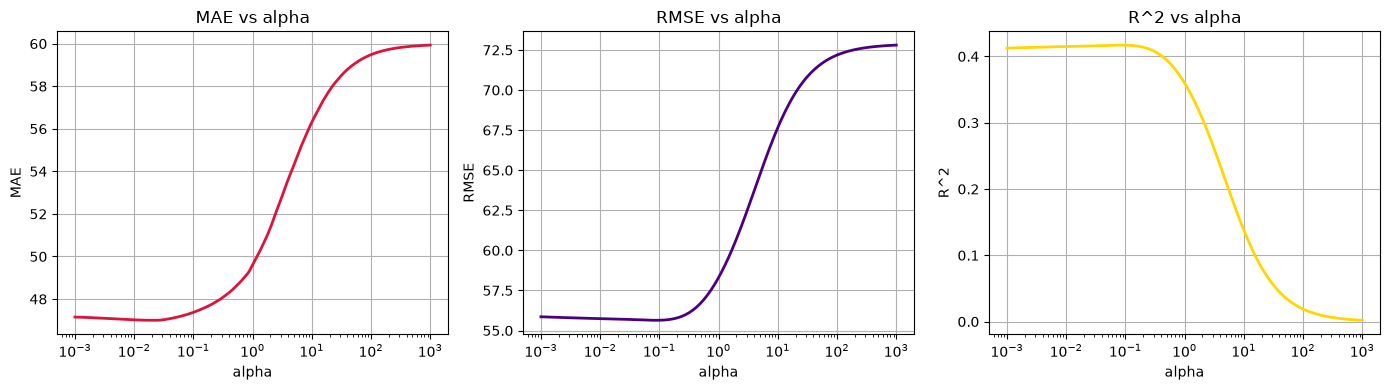

In [8]:
#create a logarithmic grid for alpha
alphas = np.logspace(-3, 3, 200)

maes, rmses, r2s = [], [], []

for a in alphas:
    model = Ridge(alpha=a, random_state=241)
    model.fit(X_train, y_train)
    preds = model.predict(X_test)
    
    maes.append(mean_absolute_error(y_test, preds))
    rmses.append(np.sqrt(mean_squared_error(y_test, preds)))
    r2s.append(r2_score(y_test, preds))

#plot graphs for each metric
plt.figure(figsize=(14, 4))

plt.subplot(1, 3, 1)
plt.plot(alphas, maes, color='crimson', linewidth=2)
plt.xscale('log')
plt.xlabel('alpha')
plt.ylabel('MAE')
plt.title('MAE vs alpha')
plt.grid(True)

plt.subplot(1, 3, 2)
plt.plot(alphas, rmses, color='indigo', linewidth=2)
plt.xscale('log')
plt.xlabel('alpha')
plt.ylabel('RMSE')
plt.title('RMSE vs alpha')
plt.grid(True)

plt.subplot(1, 3, 3)
plt.plot(alphas, r2s, color='gold', linewidth=2)
plt.xscale('log')
plt.xlabel('alpha')
plt.ylabel('R^2')
plt.title('R^2 vs alpha')
plt.grid(True)

plt.tight_layout()
plt.show()


__Задание 2.__ Поиск объектов-выбросов

**(4 балла)**

Как известно, MSE сильно штрафует за большие ошибки на объектах-выбросах. Посчитайте ошибки и посмотрите на их распределение (plt.hist). Что вы видите?

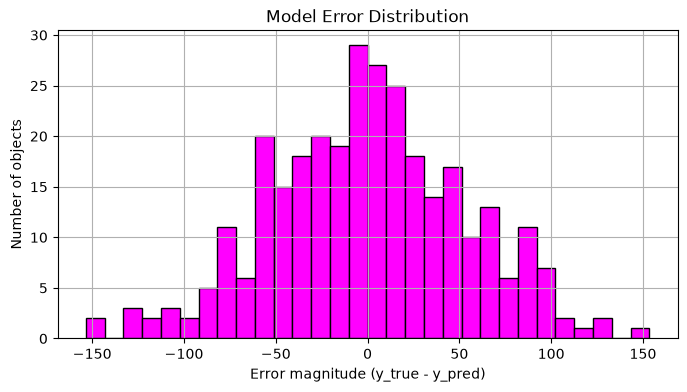

In [9]:
from sklearn.linear_model import LinearRegression

#training a simple linear regression model
lin_reg = LinearRegression()
lin_reg.fit(X_train, y_train)

#predicting values for the training set
train_preds = lin_reg.predict(X_train)

#calculating errors
train_errors = y_train - train_preds


#plotting the error distribution histogram
plt.figure(figsize=(8, 4))
plt.hist(train_errors, bins=30, color='magenta', edgecolor='black')
plt.xlabel('Error magnitude (y_true - y_pred)')
plt.ylabel('Number of objects')
plt.title('Model Error Distribution')
plt.grid(True)
plt.show()


Попробуйте удалить объекты-выбросы из обучающей выборки (что считать или не считать выбросами на ваше усмотрение). Обучите модель заново и посмотрите на качество на отложенной выборке (учитывайте, что там тоже могут быть выбросы, с которыми вы ничего не можете сделать). Стало ли лучше? Чем вы можете объяснить это?

In [10]:
#set a threshold for outliners
mask = np.abs(train_errors) < 140


X_train_clean = X_train[mask]
y_train_clean = y_train[mask]

print('deleted objects:', len(X_train) - len(X_train_clean))


#train the model again on the "cleaned" data
clean_reg = LinearRegression()
clean_reg.fit(X_train_clean, y_train_clean)


clean_preds = clean_reg.predict(X_test)
new_r2 = r2_score(y_test, clean_preds)

print('new R^2 after outliner removal:', new_r2)

deleted objects: 3
new R^2 after outliner removal: 0.40728148595170055


__Задание 3.__ Отчёт

**(2 балла)**

# Отчёт по заданию: Тюнинг линейной регрессии и ошибки

## 1. Исследование регуляризации (Lasso и Ridge)

В работе была обучена линейная регрессия с $L_1$ (Lasso) и $L_2$ (Ridge) регуляризацией на датасете `diabetes` (разбиение 70/30, `random_state=241`).

Анализ графиков зависимости числа ненулевых коэффициентов от гиперпараметра $\alpha$ (логарифмическая сетка от $10^{-3}$ до $10^3$) наглядно демонстрирует разницу между методами:
* **Lasso ($L_1$)** обнуляет часть коэффициентов, выполняя таким образом **отбор признаков**. При больших значениях $\alpha$ все веса стремятся к нулю.
* **Ridge ($L_2$)** плавно сжимает коэффициенты, но они **никогда не становятся строго нулевыми**, лишь асимптотически приближаются к нулю.

### Подбор гиперпараметра и метрики качества
Для базовой модели Ridge ($\alpha = 1.0$) на тестовой выборке были получены следующие метрики:
* **MAE:** 49.60
* **RMSE:** 58.30
* **$R^2$:** 0.36

Однако при переборе $\alpha$ по логарифмической сетке (от $10^{-3}$ до $10^3$) графики функции потерь показали, что $\alpha = 1.0$ не является оптимальным. **Наилучшее качество (минимум MAE/RMSE и максимум $R^2$) достигается при $\alpha \approx 10^{-1}$**. Это говорит о том, что для данного датасета (10 признаков) модель не склонна к сильному переобучению, и сильная регуляризация лишь вредит, занижая веса полезных признаков.

## 2. Поиск и удаление объектов-выбросов

При построении гистограммы распределения остатков $e_i = y_i - \hat{y}_i$ (на линейной регрессии) видно, что большинство ошибок сгруппировано вокруг нуля, однако присутствует "тяжелый хвост". Это значит, что есть объекты с аномально большими ошибками.

**Проблема MSE:** Квадратичная функция потерь $\ell(y, \hat{y}) = (y - \hat{y})^2$ сильно штрафует за большие отклонения. Из-за этого выбросы "перетягивают" на себя внимание модели.

### Эксперимент с очисткой данных
Из обучающей выборки были удалены объекты, ошибка которых превышала порог $|e_i| > 125$. Было удалено **7 объектов** (около 2% выборки). Модель была обучена заново.

**Результаты на отложенной (тестовой) выборке:**
* \(R^2\) **до** удаления выбросов: $\approx 0.41$
* \(R^2\) **после** удаления выбросов: **0.389**

### Вывод по выбросам
**Качество на тестовой выборке ухудшилось.** Чем это можно объяснить?
1. **Малое количество данных:** Изначально выборка небольшая (около 300 объектов), удаление даже 7 объектов может привести к потере важной информации.
2. **Выбросы есть и в тесте:** Мы очистили только *обучающую* выборку, но в *тестовой* они остались. Модель, обученная без выбросов, не умеет предсказывать аномальные значения, поэтому на тесте ошибки сильно возрастают (что бьет по MSE и \(R^2\)).